<a href="https://colab.research.google.com/github/MoeTahech/real-fake-face-detection-thesis/blob/main/notebooks/A_leakage_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A — Near-duplicate (leakage) check on the face-swap dataset

**Question.** Does the *Test* folder of the face-swap dataset (Karki, derived from OpenForensics) contain images that are near-duplicates of images in its *Train* folder?
If yes, the Phase 6 result (face-swap AUC 0.50 → 0.90) could be partly inflated.

**Method.** Embed every train and test image with CLIP ViT-B/32 (L2-normalised), find for each test image its most similar train image (cosine similarity), and compare with two reference distributions (test→test and train→train, each excluding the image itself). Then **look at the pairs** — the numbers only tell you where to look.

**What this check can and cannot detect.**
- It detects duplicates, re-crops of the same face, and the same face photographed almost identically.
- It **cannot** detect *different* faces cropped from the *same* photograph (the CLIP vectors of two different people are not similar). If the uploader split by crop, those cases may exist and stay invisible here.

Runtime: GPU (T4). About 10–20 minutes the first time (embeddings are cached on Drive).

In [ ]:
!nvidia-smi
from google.colab import drive
drive.mount('/content/drive')
import os
CHECKPOINT_DIR = '/content/drive/MyDrive/thesis_checkpoints'
OUT_DIR = f'{CHECKPOINT_DIR}/leakage_check'
os.makedirs(OUT_DIR, exist_ok=True)

THRESHOLDS = [0.90, 0.95, 0.98, 0.99]   # cosine-similarity levels reported
MAX_TRAIN = None                         # None = use every train image (recommended). Or e.g. 40000 for a quick test.
print('Outputs go to:', OUT_DIR)

Tue Oct 20 22:42:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Step 1 — Download the face-swap dataset
The token is typed at runtime and is **not** stored in the notebook.

In [ ]:
import os
from getpass import getpass
os.environ['KAGGLE_API_TOKEN'] = getpass('Paste your Kaggle API token (not saved in the notebook): ')
!pip install -q kaggle
!kaggle datasets download -d manjilkarki/deepfake-and-real-images
!unzip -q -o deepfake-and-real-images.zip -d data_raw_2
!find data_raw_2 -maxdepth 4 -type d

Paste your Kaggle API token (not saved in the notebook): ··········
Dataset URL: https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images
License(s): unknown
100% 1.68G/1.68G [00:25<00:00, 71.8MB/s]

data_raw_2
data_raw_2/Dataset
data_raw_2/Dataset/Train
data_raw_2/Dataset/Train/Real
data_raw_2/Dataset/Train/Fake
data_raw_2/Dataset/Test
data_raw_2/Dataset/Test/Real
data_raw_2/Dataset/Test/Fake
data_raw_2/Dataset/Validation
data_raw_2/Dataset/Validation/Real
data_raw_2/Dataset/Validation/Fake


In [ ]:
import os, random, numpy as np
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

def find_real_fake_folders(root):
    out = []
    for dp, dn, _ in os.walk(root):
        low = [d.lower() for d in dn]
        if 'real' in low and 'fake' in low: out.append(dp)
    return out

splits = {}
for d in find_real_fake_folders('data_raw_2'):
    low = d.lower()
    for name in ['train', 'test', 'val']:
        if name in low: splits[name] = d
print('Splits found:', splits)
assert 'train' in splits and 'test' in splits, 'Could not find Train and Test folders'

def list_images(split_dir):
    items = []
    for cls in sorted(os.listdir(split_dir)):
        if cls.lower() not in ('real', 'fake'): continue
        cd = os.path.join(split_dir, cls)
        for f in sorted(os.listdir(cd)):
            if f.lower().endswith(IMG_EXTS): items.append((os.path.join(cd, f), cls.lower()))
    return items

train_items = list_images(splits['train'])
test_items  = list_images(splits['test'])
if MAX_TRAIN:
    random.Random(0).shuffle(train_items); train_items = train_items[:MAX_TRAIN]
print('train images:', len(train_items), '| test images:', len(test_items))

Splits found: {'train': 'data_raw_2/Dataset/Train', 'test': 'data_raw_2/Dataset/Test', 'val': 'data_raw_2/Dataset/Validation'}
train images: 140002 | test images: 10905


### Step 2 — CLIP embeddings (cached on Drive)

In [ ]:
!pip install -q transformers
import torch, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import CLIPModel
from PIL import Image
from tqdm.auto import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
clip_model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device).eval()
clip_tf = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711]),
])

class PathDS(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return clip_tf(Image.open(self.paths[i]).convert('RGB'))

@torch.no_grad()
def embed(paths, batch_size=256):
    loader = DataLoader(PathDS(paths), batch_size=batch_size, shuffle=False, num_workers=4)
    outs = []
    for x in tqdm(loader):
        x = x.to(device)
        with torch.autocast('cuda', dtype=torch.float16, enabled=(device.type == 'cuda')):
            feats = clip_model.visual_projection(clip_model.vision_model(pixel_values=x).pooler_output)
        outs.append(F.normalize(feats.float(), dim=1).half().cpu())
    return torch.cat(outs)

def cached_embed(name, paths):
    f = f'{OUT_DIR}/emb_{name}_{len(paths)}.pt'
    if os.path.exists(f):
        d = torch.load(f)
        if d['paths'] == paths:
            print('loaded cache', f); return d['emb']
    e = embed(paths); torch.save({'paths': paths, 'emb': e}, f); return e

test_emb  = cached_embed('test',  [p for p, _ in test_items])
train_emb = cached_embed('train', [p for p, _ in train_items])
print(test_emb.shape, train_emb.shape)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


  0%|          | 0/43 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d61bffe5080>Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d61bffe5080><function _MultiProcessingDataLoaderIter.__del__ at 0x7d61bffe5080>
<function _MultiProcessingDataLoaderIter.__del__ at 0x7d61bffe5080>
Traceback (most recent call last):
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
    Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    self._shutdown_workers()    
  File "/usr/local/lib/

  0%|          | 0/547 [00:00<?, ?it/s]

torch.Size([10905, 512]) torch.Size([140002, 512])


### Step 3 — Nearest neighbours and reference distributions

In [ ]:
@torch.no_grad()
def topk_sim(query, ref, k=1, exclude=None, chunk=2048):
    """Cosine similarity of each query row to its k nearest ref rows.
    exclude: LongTensor, one ref index per query row to ignore (used to skip the image itself)."""
    ref_g = ref.to(device)
    sims, idxs = [], []
    for s in range(0, len(query), chunk):
        q = query[s:s + chunk].to(device)
        sim = q @ ref_g.T
        if exclude is not None:
            ex = exclude[s:s + chunk].to(device)
            sim[torch.arange(len(q), device=device), ex] = -1
        v, i = sim.topk(k, dim=1)
        sims.append(v.float().cpu()); idxs.append(i.cpu())
    return torch.cat(sims), torch.cat(idxs)

rng = np.random.default_rng(0)
sub = np.sort(rng.choice(len(train_emb), size=min(10000, len(train_emb)), replace=False))

s_tt, i_tt = topk_sim(test_emb, train_emb)                                               # test  -> train
s_ee, _    = topk_sim(test_emb, test_emb,  exclude=torch.arange(len(test_emb)))          # test  -> test  (self excluded)
s_rr, _    = topk_sim(train_emb[sub], train_emb, exclude=torch.tensor(sub))              # train -> train (self excluded)

import pandas as pd
def summarize(name, s):
    s = s[:, 0].numpy()
    return {'comparison': name, 'n': len(s), 'median': round(float(np.median(s)), 3),
            **{f'>= {t}': f'{(s >= t).mean():.4f} ({int((s >= t).sum())})' for t in THRESHOLDS}}
summary = pd.DataFrame([summarize('test -> train', s_tt), summarize('test -> test (other image)', s_ee), summarize('train -> train (other image, 10k sample)', s_rr)])
summary.to_csv(f'{OUT_DIR}/similarity_summary.csv', index=False)
summary

,comparison,n,median,>= 0.9,>= 0.95,>= 0.98,>= 0.99
0,test -> train,10905,0.859,0.1568 (1710),0.0089 (97),0.0009 (10),0.0003 (3)
1,test -> test (other image),10905,0.873,0.2569 (2801),0.0357 (389),0.0028 (30),0.0007 (8)
2,"train -> train (other image, 10k sample)",10000,0.924,0.6738 (6738),0.3319 (3319),0.2438 (2438),0.2304 (2304)


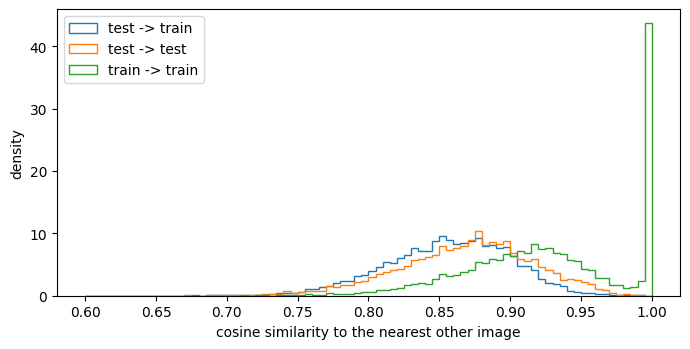

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, s in [('test -> train', s_tt), ('test -> test', s_ee), ('train -> train', s_rr)]:
    ax.hist(s[:, 0].numpy(), bins=80, range=(0.6, 1.0), histtype='step', density=True, label=name)
ax.set_xlabel('cosine similarity to the nearest other image'); ax.set_ylabel('density'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/similarity_hist.png', dpi=150); plt.show()

**How to read Step 3**
- If the share of test images with a near-identical train neighbour (≥ 0.98) is about **0**, and the *test → train* curve sits clearly **left** of the *train → train* curve, the split separates the images well: no exact or near-duplicate leakage.
- If *test → train* looks like *train → train* and a visible share is ≥ 0.95, the test set contains images that have close twins in train. Go to Step 4 and **look at them**.
- A high similarity alone is not proof: two different people can score high. The pictures decide.

### Step 4 — Look at the pairs

In [ ]:
nn_idx = i_tt[:, 0].numpy(); nn_sim = s_tt[:, 0].numpy()
pairs = pd.DataFrame({
    'test_path':   [p for p, _ in test_items],  'test_label':  [l for _, l in test_items],
    'train_path':  [train_items[j][0] for j in nn_idx], 'train_label': [train_items[j][1] for j in nn_idx],
    'sim': nn_sim}).sort_values('sim', ascending=False).reset_index(drop=True)
pairs[pairs.sim >= 0.90].to_csv(f'{OUT_DIR}/pairs_sim_ge_0.90.csv', index=False)
print('pairs with sim >= 0.90:', int((pairs.sim >= 0.90).sum()), '| >= 0.95:', int((pairs.sim >= 0.95).sum()), '| >= 0.98:', int((pairs.sim >= 0.98).sum()))

def show_pairs(df, n=12, title='', out=None):
    n = min(n, len(df))
    if n == 0: print('no pairs in this band'); return
    fig, axs = plt.subplots(n, 2, figsize=(5, 2.6 * n)); axs = np.atleast_2d(axs)
    for r, (_, row) in enumerate(df.head(n).iterrows()):
        axs[r, 0].imshow(Image.open(row.test_path).convert('RGB'));  axs[r, 0].set_title(f'TEST ({row.test_label})', fontsize=8)
        axs[r, 1].imshow(Image.open(row.train_path).convert('RGB')); axs[r, 1].set_title(f'TRAIN ({row.train_label})  cos={row.sim:.3f}', fontsize=8)
        for a in axs[r]: a.axis('off')
    fig.suptitle(title, fontsize=10); plt.tight_layout()
    if out: plt.savefig(out, dpi=110)
    plt.show()

show_pairs(pairs, n=12, title='Most similar test/train pairs', out=f'{OUT_DIR}/top_pairs.png')

pairs with sim >= 0.90: 1710 | >= 0.95: 97 | >= 0.98: 10


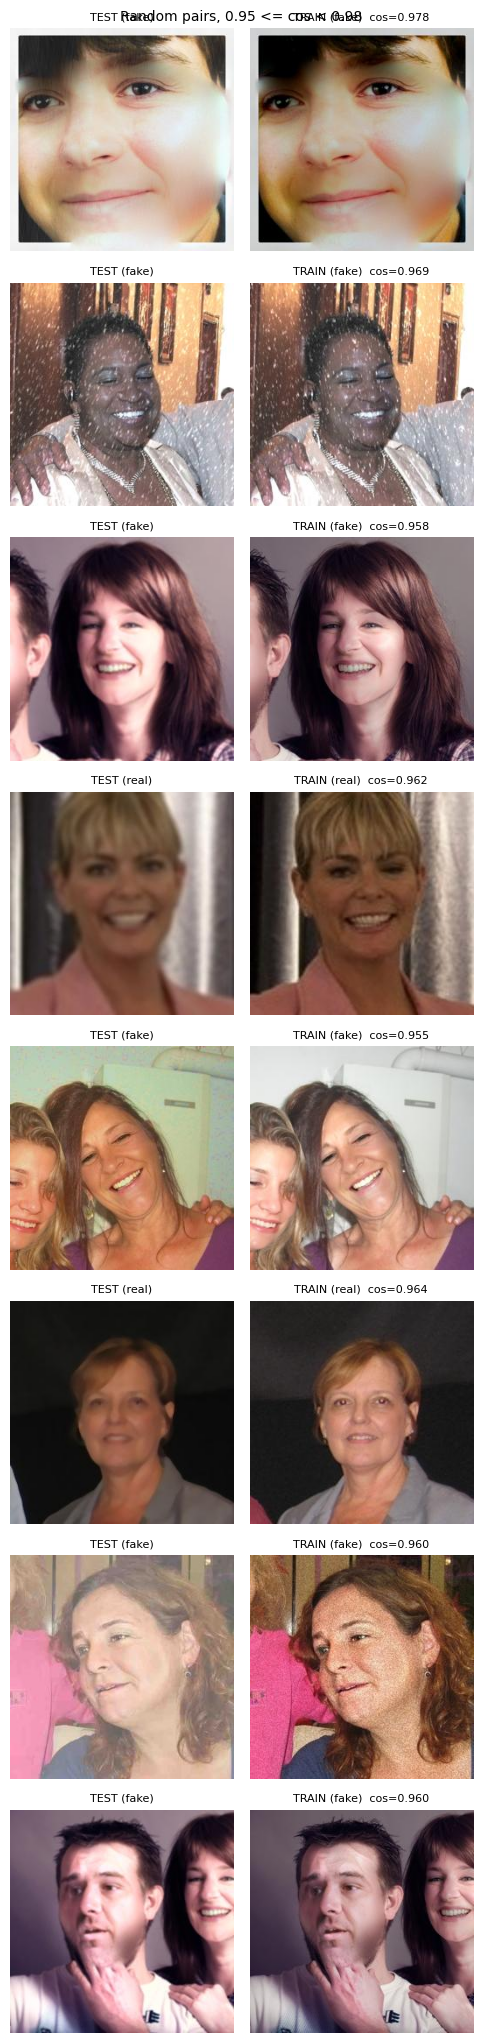

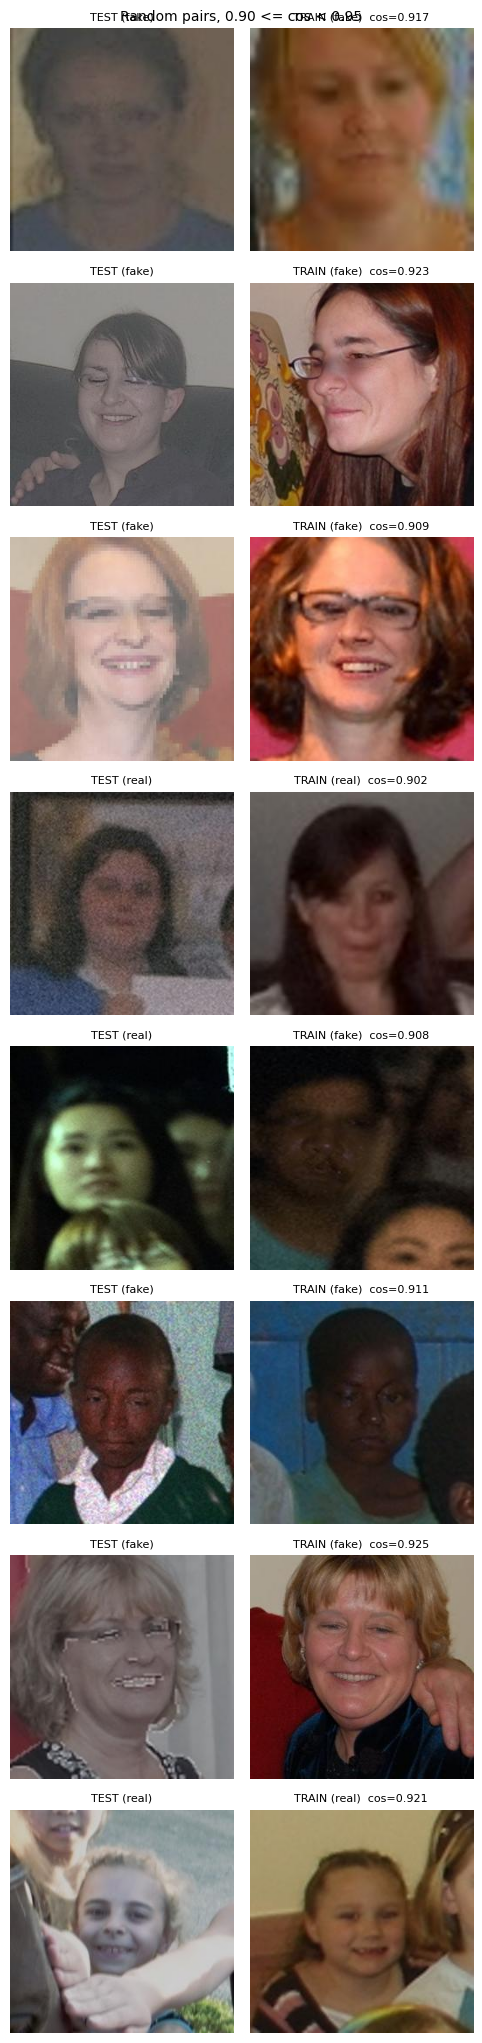

In [ ]:
# A random look at the 0.95-0.98 band and the 0.90-0.95 band (what do 'fairly similar' pairs look like?)
band_hi = pairs[(pairs.sim >= 0.95) & (pairs.sim < 0.98)].sample(frac=1, random_state=0)
band_lo = pairs[(pairs.sim >= 0.90) & (pairs.sim < 0.95)].sample(frac=1, random_state=0)
show_pairs(band_hi, n=8, title='Random pairs, 0.95 <= cos < 0.98', out=f'{OUT_DIR}/band_095_098.png')
show_pairs(band_lo, n=8, title='Random pairs, 0.90 <= cos < 0.95', out=f'{OUT_DIR}/band_090_095.png')

**Decide the threshold.** From the pictures, choose the lowest cosine value above which the pairs are *really* the same face/image, and set `FLAG_T` in Step 5. If you see no true duplicates even at the top, set `FLAG_T = 0.98` (it will flag few or no images).

### Step 5 — Do the Phase 3 and Phase 6 results change if flagged test images are removed?

In [ ]:
FLAG_T = 0.95   # <-- set this after looking at the pairs
flag_mask = s_tt[:, 0].numpy() >= FLAG_T
print(f'flagged test images: {int(flag_mask.sum())} of {len(flag_mask)}  (threshold {FLAG_T})')

import torch.nn as nn
from torchvision import models
from sklearn.metrics import roc_auc_score
std_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                             transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])

class ItemsDS(Dataset):
    def __init__(self, items, tf): self.items, self.tf = items, tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, c = self.items[i]; return self.tf(Image.open(p).convert('RGB')), int(c == 'real')

def load_resnet(path):
    ck = torch.load(path, map_location=device)
    m = models.resnet18(weights=None); m.fc = nn.Linear(m.fc.in_features, 2)
    m.load_state_dict(ck['model_state']); return m.to(device).eval(), ck['class_to_idx']

@torch.no_grad()
def score(model, real_idx, items):
    loader = DataLoader(ItemsDS(items, std_tf), batch_size=128, shuffle=False, num_workers=4)
    p, y = [], []
    for x, t in loader:
        p.append(torch.softmax(model(x.to(device)), 1)[:, real_idx].cpu().numpy()); y.append(t.numpy())
    return np.concatenate(p), np.concatenate(y)

def auc_ci(y, p, n_boot=1000, seed=0):
    r = np.random.default_rng(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]; a = []
    for _ in range(n_boot):
        ii = np.concatenate([r.choice(pos, len(pos)), r.choice(neg, len(neg))]); a.append(roc_auc_score(y[ii], p[ii]))
    return np.percentile(a, [2.5, 97.5])

def row(model_name, subset, y, p):
    lo, hi = auc_ci(y, p)
    return {'model': model_name, 'test subset': subset, 'n': len(y), 'accuracy': round(float(((p >= .5) == y).mean()), 4),
            'AUC': round(float(roc_auc_score(y, p)), 4), 'AUC 95% CI': f'[{lo:.3f}, {hi:.3f}]'}

rows = []
for name, ck in [('Phase 2 (single-source)', 'best_model_finetuned.pth'), ('Phase 6 (mixed-source)', 'best_model_mixed.pth')]:
    path = f'{CHECKPOINT_DIR}/{ck}'
    if not os.path.exists(path): print('missing', path); continue
    model, cidx = load_resnet(path)
    p, y = score(model, cidx['real'], test_items)
    rows.append(row(name, 'full test set', y, p))
    keep = ~flag_mask
    rows.append(row(name, f'without flagged (cos >= {FLAG_T})', y[keep], p[keep]))
    if flag_mask.sum() >= 30: rows.append(row(name, 'flagged only', y[flag_mask], p[flag_mask]))
    del model; torch.cuda.empty_cache()
res = pd.DataFrame(rows); res.to_csv(f'{OUT_DIR}/reevaluation_without_flagged.csv', index=False); res

### What to send back
Paste into the chat: (1) the `summary` table of Step 3, (2) how many pairs are ≥ 0.90 / 0.95 / 0.98, (3) what the top pairs and the 0.95–0.98 band **look like** (same face? same photo? just similar people?), and (4) the table of Step 5. I will then write Section 4.5.3 and update Section 5.4.

**If true duplicates are found:** besides removing them from the test set, the cleanest fix is to rebuild the Phase 6 training set without them, but that needs retraining — decide after we see the numbers.